# Double descent — book graphics 1

Static matplotlib version of the `P8_15V2` manim scene in `p8_15.py`, for book SVGs.

Five panels, each saved as its own SVG (plus a PNG preview) with identical axis limits so they line up in Illustrator:

1. **Panels 1–4** — degree 1, 2, 3, 4 Legendre fits on top of the training points, testing points, and the underlying function $f(x) = \tfrac{1}{2}x^2$.
2. **Panel 5** — training and testing MSE as a function of polynomial degree.

Data, seed, train/test split, and the pseudoinverse Legendre fit are identical to the manim scene, so the numbers match the video.


## 1. Config

In [31]:
import os
from pathlib import Path
import numpy as np
import scipy.special
import matplotlib.pyplot as plt

# ── Book palette ───────────────────────────────────────────────────────────
CHILL_BROWN = '#948979'
LT_BLUE     = '#5badb6'
ORANGE      = '#eb8423'
GREEN       = '#419c52'   # from the CMYK swatch conversion (C76 M15 Y90 K2) — swap if you have a house value
BLUE        = '#236c94'
RED         = '#d73b2f'
PINK        = '#ed5e78'

AXIS_COLOR   = CHILL_BROWN
CURVE_COLOR  = CHILL_BROWN   # underlying function f(x)
TRAIN_COLOR  = LT_BLUE
TEST_COLOR   = ORANGE
FIT_COLORS   = {1: GREEN, 2: BLUE, 3: RED, 4: PINK}

# ── Data (matches p8_15.py) ────────────────────────────────────────────────
RANDOM_SEED = 428
N_POINTS    = 10
NOISE_LEVEL = 0.2
TRAIN_FRAC  = 0.5
X_MIN, X_MAX = -2.0, 2.0
DEGREES     = [1, 2, 3, 4]
def f(x): return 0.5 * x**2

# ── Figure styling ─────────────────────────────────────────────────────────
PANEL_SIZE      = (4.0, 3.4)   # inches, per panel
LINEWIDTH       = 2.0          # fit lines + underlying curve
AXIS_LINEWIDTH  = 1.0
DOT_SIZE        = 36           # scatter marker area (pt^2)
FONTSIZE        = 10
XLIM            = (X_MIN, X_MAX)
YLIM            = (-0.5, 2.0)
MSE_YLIM        = None         # None = auto from data, or e.g. (0, 1.5)
SPINES          = 'lb'         # 'lb' = left+bottom only, 'box' = all four
SHOW_TICKS      = True         # False = bare axes (add numbers in Illustrator)
PREV_FIT_ALPHA  = 0.3          # earlier-degree fits drawn faded in later panels (0 = don't draw them)
CURVE_ALPHA     = 1.0
CURVE_LINESTYLE = '-'          # e.g. '--' to dash the underlying function
MSE_SHOW_TRAIN  = True
MSE_SHOW_TEST   = True
MSE_CONNECT     = True         # connect MSE dots with lines
MSE_LOG_Y       = False        # True for log-scale MSE axis (degree-4 train error is ~0, so it gets clipped)
TRANSPARENT     = True

# ── Output ─────────────────────────────────────────────────────────────────
OUT_DIR = Path('/Users/stephen/Library/CloudStorage/Dropbox-Stephencwelch/welch_labs/ai_book_vol_2/5_double_descent/graphics/initial_curve_fits')   # relative to this notebook
SAVE    = True

plt.rcParams['svg.fonttype'] = 'none'   # keep text editable in Illustrator
plt.rcParams['font.family']  = 'sans-serif'
OUT_DIR.mkdir(parents=True, exist_ok=True)


## 2. Fit helpers (from `p8_15.py`)

In [26]:
def fit_legendre_pinv(x_train, y_train, degree, x_min=X_MIN, x_max=X_MAX):
    """Fit Legendre polynomial using pseudoinverse."""
    x_scaled = 2 * (x_train - x_min) / (x_max - x_min) - 1
    feature_degrees = np.arange(degree + 1)[:, None]
    X_train_poly = scipy.special.eval_legendre(feature_degrees, x_scaled).T
    return np.linalg.pinv(X_train_poly) @ y_train

def eval_legendre_poly(beta, x, degree, x_min=X_MIN, x_max=X_MAX):
    """Evaluate Legendre polynomial with given coefficients."""
    x_scaled = 2 * (x - x_min) / (x_max - x_min) - 1
    feature_degrees = np.arange(degree + 1)[:, None]
    X_poly = scipy.special.eval_legendre(feature_degrees, x_scaled).T
    return X_poly @ beta

def get_noisy_data(n_points=N_POINTS, noise_level=NOISE_LEVEL, random_seed=RANDOM_SEED):
    np.random.seed(random_seed)
    x = np.random.uniform(X_MIN, X_MAX, n_points)
    y = f(x) + noise_level * np.random.randn(n_points)
    return x, y


## 3. Data + fits

In [27]:
x, y = get_noisy_data()
n_train = int(np.floor(N_POINTS * TRAIN_FRAC))
x_train, y_train = x[:n_train], y[:n_train]
x_test,  y_test  = x[n_train:], y[n_train:]

all_x = np.linspace(X_MIN, X_MAX, 256)
all_y = f(all_x)

fits = {}
for d in DEGREES:
    beta = fit_legendre_pinv(x_train, y_train, d)
    fits[d] = dict(
        beta      = beta,
        curve     = eval_legendre_poly(beta, all_x, d),
        train_mse = np.mean((y_train - eval_legendre_poly(beta, x_train, d))**2),
        test_mse  = np.mean((y_test  - eval_legendre_poly(beta, x_test,  d))**2),
    )

print(f"{'degree':>6} {'train MSE':>10} {'test MSE':>10}")
for d in DEGREES:
    print(f"{d:>6} {fits[d]['train_mse']:>10.6f} {fits[d]['test_mse']:>10.6f}")


degree  train MSE   test MSE
     1   0.221350   0.691636
     2   0.031825   0.079449
     3   0.000803   0.727023
     4   0.000000   1.328535


## 4. Panel renderers

In [28]:
def style_ax(ax, color=AXIS_COLOR):
    if SPINES == 'lb':
        ax.spines[['top', 'right']].set_visible(False)
    ax.spines[:].set_color(color)
    ax.spines[:].set_linewidth(AXIS_LINEWIDTH)
    ax.tick_params(colors=color, labelsize=FONTSIZE, width=AXIS_LINEWIDTH, which='both')
    ax.xaxis.label.set_color(color)
    ax.yaxis.label.set_color(color)
    if not SHOW_TICKS:
        ax.set_xticks([]); ax.set_yticks([])

def draw_fit_panel(ax, degree):
    """Underlying curve + train/test points + fit of `degree` (earlier fits faded)."""
    ax.plot(all_x, all_y, color=CURVE_COLOR, lw=LINEWIDTH, ls=CURVE_LINESTYLE,
            alpha=CURVE_ALPHA, zorder=1, solid_capstyle='round')
    if PREV_FIT_ALPHA > 0:
        for d in DEGREES:
            if d < degree:
                ax.plot(all_x, fits[d]['curve'], color=FIT_COLORS[d], lw=LINEWIDTH,
                        alpha=PREV_FIT_ALPHA, zorder=2, solid_capstyle='round')
    ax.plot(all_x, fits[degree]['curve'], color=FIT_COLORS[degree], lw=LINEWIDTH,
            zorder=4, solid_capstyle='round')
    ax.scatter(x_train, y_train, s=DOT_SIZE, color=TRAIN_COLOR, zorder=3, linewidths=0)
    ax.scatter(x_test,  y_test,  s=DOT_SIZE, color=TEST_COLOR,  zorder=3, linewidths=0)
    ax.set_xlim(*XLIM); ax.set_ylim(*YLIM)
    ax.set_xticks(np.arange(XLIM[0], XLIM[1] + 1e-9, 1.0))
    ax.set_yticks(np.arange(0, YLIM[1] + 1e-9, 1.0))
    style_ax(ax)

def draw_mse_panel(ax):
    """Train / test MSE vs polynomial degree."""
    degs  = np.array(DEGREES)
    tr    = np.array([fits[d]['train_mse'] for d in DEGREES])
    te    = np.array([fits[d]['test_mse']  for d in DEGREES])
    ls    = '-' if MSE_CONNECT else 'none'
    if MSE_SHOW_TRAIN:
        ax.plot(degs, tr, ls=ls, lw=LINEWIDTH, color=TRAIN_COLOR, zorder=2, alpha=0.6)
        ax.scatter(degs, tr, s=DOT_SIZE, color=TRAIN_COLOR, zorder=3, linewidths=0)
    if MSE_SHOW_TEST:
        ax.plot(degs, te, ls=ls, lw=LINEWIDTH, color=TEST_COLOR, zorder=2, alpha=0.6)
        ax.scatter(degs, te, s=DOT_SIZE, color=TEST_COLOR, zorder=3, linewidths=0)
    ax.set_xlim(degs.min() - 0.5, degs.max() + 0.5)
    ax.set_xticks(degs)
    if MSE_LOG_Y:
        ax.set_yscale('log')
    else:
        if MSE_YLIM is None:
            top = max(tr.max() if MSE_SHOW_TRAIN else 0, te.max() if MSE_SHOW_TEST else 0)
            ax.set_ylim(0, 1.1 * top)
        else:
            ax.set_ylim(*MSE_YLIM)
    style_ax(ax)


## 5. Preview — all five panels

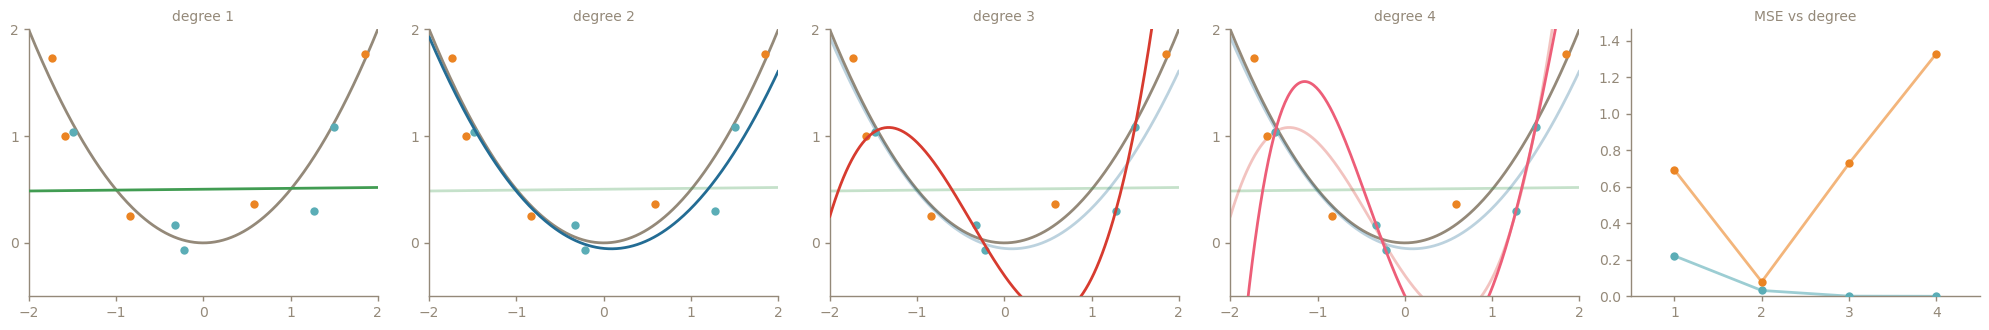

In [29]:
fig, axes = plt.subplots(1, 5, figsize=(PANEL_SIZE[0] * 5, PANEL_SIZE[1]))
for ax, d in zip(axes[:4], DEGREES):
    draw_fit_panel(ax, d)
    ax.set_title(f'degree {d}', color=AXIS_COLOR, fontsize=FONTSIZE)
draw_mse_panel(axes[4])
axes[4].set_title('MSE vs degree', color=AXIS_COLOR, fontsize=FONTSIZE)
plt.tight_layout()
plt.show()


## 6. Export — one SVG (+ PNG) per panel

In [30]:
if SAVE:
    for d in DEGREES:
        fig, ax = plt.subplots(figsize=PANEL_SIZE)
        draw_fit_panel(ax, d)
        for ext in ('svg', 'png'):
            fig.savefig(OUT_DIR / f'panel_{d}_degree_{d}_fit.{ext}', dpi=300,
                        transparent=TRANSPARENT, bbox_inches='tight')
        plt.close(fig)

    fig, ax = plt.subplots(figsize=PANEL_SIZE)
    draw_mse_panel(ax)
    for ext in ('svg', 'png'):
        fig.savefig(OUT_DIR / f'panel_5_mse_vs_degree.{ext}', dpi=300,
                    transparent=TRANSPARENT, bbox_inches='tight')
    plt.close(fig)

    print('saved to', OUT_DIR.resolve())
    for p in sorted(OUT_DIR.glob('*.svg')):
        print('  ', p.name)


saved to /Users/stephen/Library/CloudStorage/Dropbox-Stephencwelch/welch_labs/ai_book_vol_2/5_double_descent/graphics
   panel_1_degree_1_fit.svg
   panel_2_degree_2_fit.svg
   panel_3_degree_3_fit.svg
   panel_4_degree_4_fit.svg
   panel_5_mse_vs_degree.svg


In [24]:
OUT_DIR

PosixPath('Users/stephen/Library/CloudStorage/Dropbox-Stephencwelch/welch_labs/ai_book_vol_2/5_double_descent/graphics')